# 🌊 AquaYOLO: Automated Marine Dataset Download & YOLO Training

This notebook downloads your 3 marine datasets directly inside Google Colab (no slow Drive uploads needed!), harmonizes conflicting labels into a unified marine taxonomy, and runs high-accuracy YOLO training.

### 📌 What This Notebook Does:
1. **⚡ Fast Direct In-Colab Download**: Directly downloads at 100+ MB/s from Kaggle & Roboflow:
   - `slavkoprytula/aquarium-data-cots` (Kaggle)
   - `vencerlanz09/sea-animals-image-dataste` (Kaggle)
   - `boats-hr2s2/marine-life-pzpu1` (Roboflow)
2. **🔄 Automated Multi-Dataset Harmonizer**: Resolves class ID collisions between datasets and converts classification images into detection targets.
3. **🎯 High-Accuracy Training**: Trains YOLOv8 with transfer learning, cosine learning rate decay, and mosaic augmentation.
4. **📊 Complete Metric Graphs**: Displays all generated metric graphs directly in notebook outputs:
   - `results.png` (Training & Validation Losses, Precision, Recall, mAP@0.50, mAP@0.50:0.95)
   - `confusion_matrix.png` & `confusion_matrix_normalized.png`
   - `PR_curve.png` (Precision-Recall curve)
   - `F1_curve.png`, `P_curve.png`, `R_curve.png`
   - `val_batch0_pred.jpg` (Visual prediction comparisons)

## 🚀 Step 1: Check GPU Runtime
Make sure you are using a GPU runtime (Runtime -> Change runtime type -> T4 GPU).

In [ ]:
!nvidia-smi

## 📦 Step 2: Clone AquaYOLO Repository & Install Dependencies

In [1]:
# Clone repository from GitHub
!git clone https://github.com/Aravind8833/AquaYOLO.git
%cd /content/AquaYOLO

# Install dependencies
!pip install -q ultralytics opencv-python matplotlib seaborn pyyaml pandas pillow tqdm kagglehub roboflow
print('\n Environment ready!')

Cloning into 'AquaYOLO'...
remote: Enumerating objects: 58, done.
remote: Counting objects: 100% (11/11), done.
remote: Compressing objects: 100% (8/8), done.
remote: Total 58 (delta 5), reused 8 (delta 3), pack-reused 47 (from 1)
Receiving objects: 100% (58/58), 174.64 MiB | 34.02 MiB/s, done.
Resolving deltas: 100% (9/9), done.
Updating files: 100% (44/44), done.
/content/AquaYOLO

 Environment ready!


## ⚡ Step 3: Direct Fast Download from Kaggle & Roboflow

Instead of waiting hours uploading gigabytes from home to Google Drive, Colab can download them in **under 1–2 minutes** at 100+ MB/s!

### 🔑 Kaggle Authentication (Takes 10 seconds):
1. Go to [kaggle.com](https://www.kaggle.com/) -> Profile icon (top right) -> **Settings**.
2. Scroll to the **API** section and click **Create New Token** (downloads `kaggle.json`).
3. Enter your **Kaggle Username** and **Key** below (or upload `kaggle.json`).

In [2]:
import os
from pathlib import Path
import kagglehub

# =====================================================================
# ⚙️ OPTION 1: KAGGLE CREDENTIALS (ENTER YOUR USERNAME & KEY)
# =====================================================================
# Open your downloaded kaggle.json in notepad and paste username & key here:
os.environ["KAGGLE_USERNAME"] = "aravvidragon"
os.environ["KAGGLE_KEY"] = "KGAT_880f568f48fd64b65d0ee1fd6cba7f3a"

# !pip install roboflow

# from roboflow import Roboflow
# rf = Roboflow(api_key="ZThcxLkiTUfSMAyN9n7i")
# project = rf.workspace("boats-hr2s2").project("marine-life-pzpu1")
# version = project.version(4)
# dataset = version.download("yolov8")


# Or upload kaggle.json directly if you prefer:
if not os.path.exists(os.path.expanduser("~/.kaggle/kaggle.json")) and os.environ["KAGGLE_USERNAME"] == "your_kaggle_username":
    print("Upload your kaggle.json file:")
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
        for fn in uploaded:
            os.rename(fn, os.path.expanduser(f"~/.kaggle/{fn}"))
        os.chmod(os.path.expanduser("~/.kaggle/kaggle.json"), 0o600)

# 1. Download Kaggle Dataset 1: aquarium-data-cots
print("\n1. Downloading slavkoprytula/aquarium-data-cots from Kaggle...")
path_cots = kagglehub.dataset_download("slavkoprytula/aquarium-data-cots")
print(f"   COTS downloaded to: {path_cots}")

# 2. Download Kaggle Dataset 2: sea-animals-image-dataste
print("\n2. Downloading vencerlanz09/sea-animals-image-dataste from Kaggle...")
path_sea = kagglehub.dataset_download("vencerlanz09/sea-animals-image-dataste")
print(f"   Sea Animals downloaded to: {path_sea}")


1. Downloading slavkoprytula/aquarium-data-cots from Kaggle...
Using Colab cache for faster access to the 'aquarium-data-cots' dataset.
   COTS downloaded to: /kaggle/input/aquarium-data-cots

2. Downloading vencerlanz09/sea-animals-image-dataste from Kaggle...


100%|██████████| 312M/312M [00:02<00:00, 156MB/s]

Extracting files...


   Sea Animals downloaded to: /root/.cache/kagglehub/datasets/vencerlanz09/sea-animals-image-dataste/versions/5


### 🐠 Download Roboflow Dataset (`marine-life-pzpu1`)

For your Roboflow dataset (`https://universe.roboflow.com/boats-hr2s2/marine-life-pzpu1`):
- On the dataset page, click **Download Dataset** -> Select **YOLOv8** -> Choose **Show Code**.
- Copy and paste either your **Roboflow API Key** OR the **curl download command** below.

In [3]:
import subprocess
from pathlib import Path

ROBOFLOW_DOWNLOAD_DIR = Path("/content/downloads/marine_life_roboflow")
ROBOFLOW_DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

# =====================================================================
# ⚙️ PASTE YOUR ROBOFLOW DOWNLOAD CURL COMMAND OR API KEY HERE:
# =====================================================================
# Method A: If you have your Roboflow API key:
ROBOFLOW_API_KEY = "ZThcxLkiTUfSMAyN9n7i"  # e.g. "abc123xyz"

# Method B: Or if you have the curl download URL snippet:
ROBOFLOW_CURL_URL = ""  # e.g. "https://universe.roboflow.com/ds/..."
# =====================================================================

path_roboflow = None

if ROBOFLOW_API_KEY:
    from roboflow import Roboflow
    print("Downloading from Roboflow via Python API...")
    rf = Roboflow(api_key=ROBOFLOW_API_KEY)
    project = rf.workspace("boats-hr2s2").project("marine-life-pzpu1")
    dataset = project.version(1).download("yolov8", location=str(ROBOFLOW_DOWNLOAD_DIR))
    path_roboflow = ROBOFLOW_DOWNLOAD_DIR
    print(f" Roboflow dataset downloaded to: {path_roboflow}")
elif ROBOFLOW_CURL_URL:
    print("Downloading from Roboflow via curl...")
    zip_dest = ROBOFLOW_DOWNLOAD_DIR / "roboflow.zip"
    subprocess.run(f"curl -L '{ROBOFLOW_CURL_URL}' > '{zip_dest}'", shell=True, check=True)
    subprocess.run(f"unzip -q '{zip_dest}' -d '{ROBOFLOW_DOWNLOAD_DIR}'", shell=True, check=True)
    path_roboflow = ROBOFLOW_DOWNLOAD_DIR
    print(f" Roboflow dataset downloaded and unzipped to: {path_roboflow}")
else:
    print("ℹ️ Note: If you don't have the Roboflow snippet right now, training will proceed using the two Kaggle datasets!")

loading Roboflow workspace...
loading Roboflow project...
 Roboflow dataset downloaded to: /content/downloads/marine_life_roboflow


## 🔄 Step 4: Harmonize & Merge Datasets (Zero Class Collisions)

Runs `dataset_merger.py` to:
- Remap conflicting class IDs from all sources into a unified marine taxonomy.
- Convert classification images (`sea-animals-image-dataste`) into valid detection targets.
- Build clean `/content/dataset` with balanced train, val, test splits and an updated `data.yaml`.

In [4]:
from dataset_merger import merge_datasets

# Collect all downloaded dataset directories
downloaded_sources = [p for p in [path_cots, path_sea, path_roboflow] if p is not None and Path(p).exists()]

print(f"Datasets ready for harmonization: {len(downloaded_sources)}")
for s in downloaded_sources:
    print(f"  📂 {Path(s).name}")

LOCAL_DATASET_DIR = Path("/content/dataset")
TEMP_EXTRACT_DIR = Path("/content/temp_extract")

# Run merger
DATA_YAML_PATH = merge_datasets(downloaded_sources, LOCAL_DATASET_DIR, TEMP_EXTRACT_DIR)
print(f"\n Unified dataset ready: {DATA_YAML_PATH}")

Datasets ready for harmonization: 3
  📂 aquarium-data-cots
  📂 5
  📂 marine_life_roboflow
AQUAYOLO MULTI-DATASET MERGING & REMAPPING
-> Reading directory: aquarium-data-cots
-> Detected YOLO Object Detection format in aquarium-data-cots
[ds1_aquarium-data-cots] Found 7 source classes; mapped 7 to unified taxonomy.
  Processed 511 images from aquarium-data-cots

-> Reading directory: 5
-> Detected Image Classification folder structure in 5
[ds2_5] Matched 15 classification categories to detection classes.
  Processed 8213 images from 5

-> Reading directory: marine_life_roboflow
-> Detected Image Classification folder structure in marine_life_roboflow
[ds3_marine_life_roboflow] Matched 0 classification categories to detection classes.
  Processed 0 images from marine_life_roboflow

MERGE COMPLETE SUMMARY
  Split TRAIN : 7013 images, 7009 label files
  Split VAL   : 1648 images, 1648 label files
  Split TEST  : 63 images, 63 label files

Unified config created at: /content/dataset/data.y

## 🏋️ Step 5: High-Accuracy YOLO Training
Trains YOLOv8 with transfer learning, cosine learning rate decay, and mosaic augmentation to achieve high accuracy (>75% mAP50).

In [5]:
# Run high-accuracy training
!python train_yolo.py \
    --data "{DATA_YAML_PATH}" \
    --model yolov8s.pt \
    --epochs 50 \
    --batch 16 \
    --imgsz 640 \
    --project /content/AquaYOLO/runs/yolo_train \
    --name colab_run

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
AQUAYOLO HIGH-ACCURACY YOLO TRAINING
Data config : /content/dataset/data.yaml
Base model  : yolov8s.pt
Epochs      : 50
Batch size  : 16
Image size  : 640
Output      : /content/AquaYOLO/runs/yolo_train/colab_run
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset/data_resolved.yaml, degrees=0.0, deterministic=True, device=, 

## 📊 Step 6: Display All Generated Metric Graphs
Displays every metric graph generated by YOLO directly in the notebook output:
1. **Training & Validation Loss / Metrics Curve** (`results.png`)
2. **Confusion Matrix & Normalized Confusion Matrix** (`confusion_matrix.png`)
3. **Precision-Recall Curve** (`PR_curve.png`)
4. **F1-Confidence Curve** (`F1_curve.png`)
5. **Precision & Recall Curves** (`P_curve.png`, `R_curve.png`)
6. **Validation Ground Truth vs Model Predictions** (`val_batch0_labels.jpg`, `val_batch0_pred.jpg`)

TRAINING & VALIDATION METRICS OVER EPOCHS: results.png


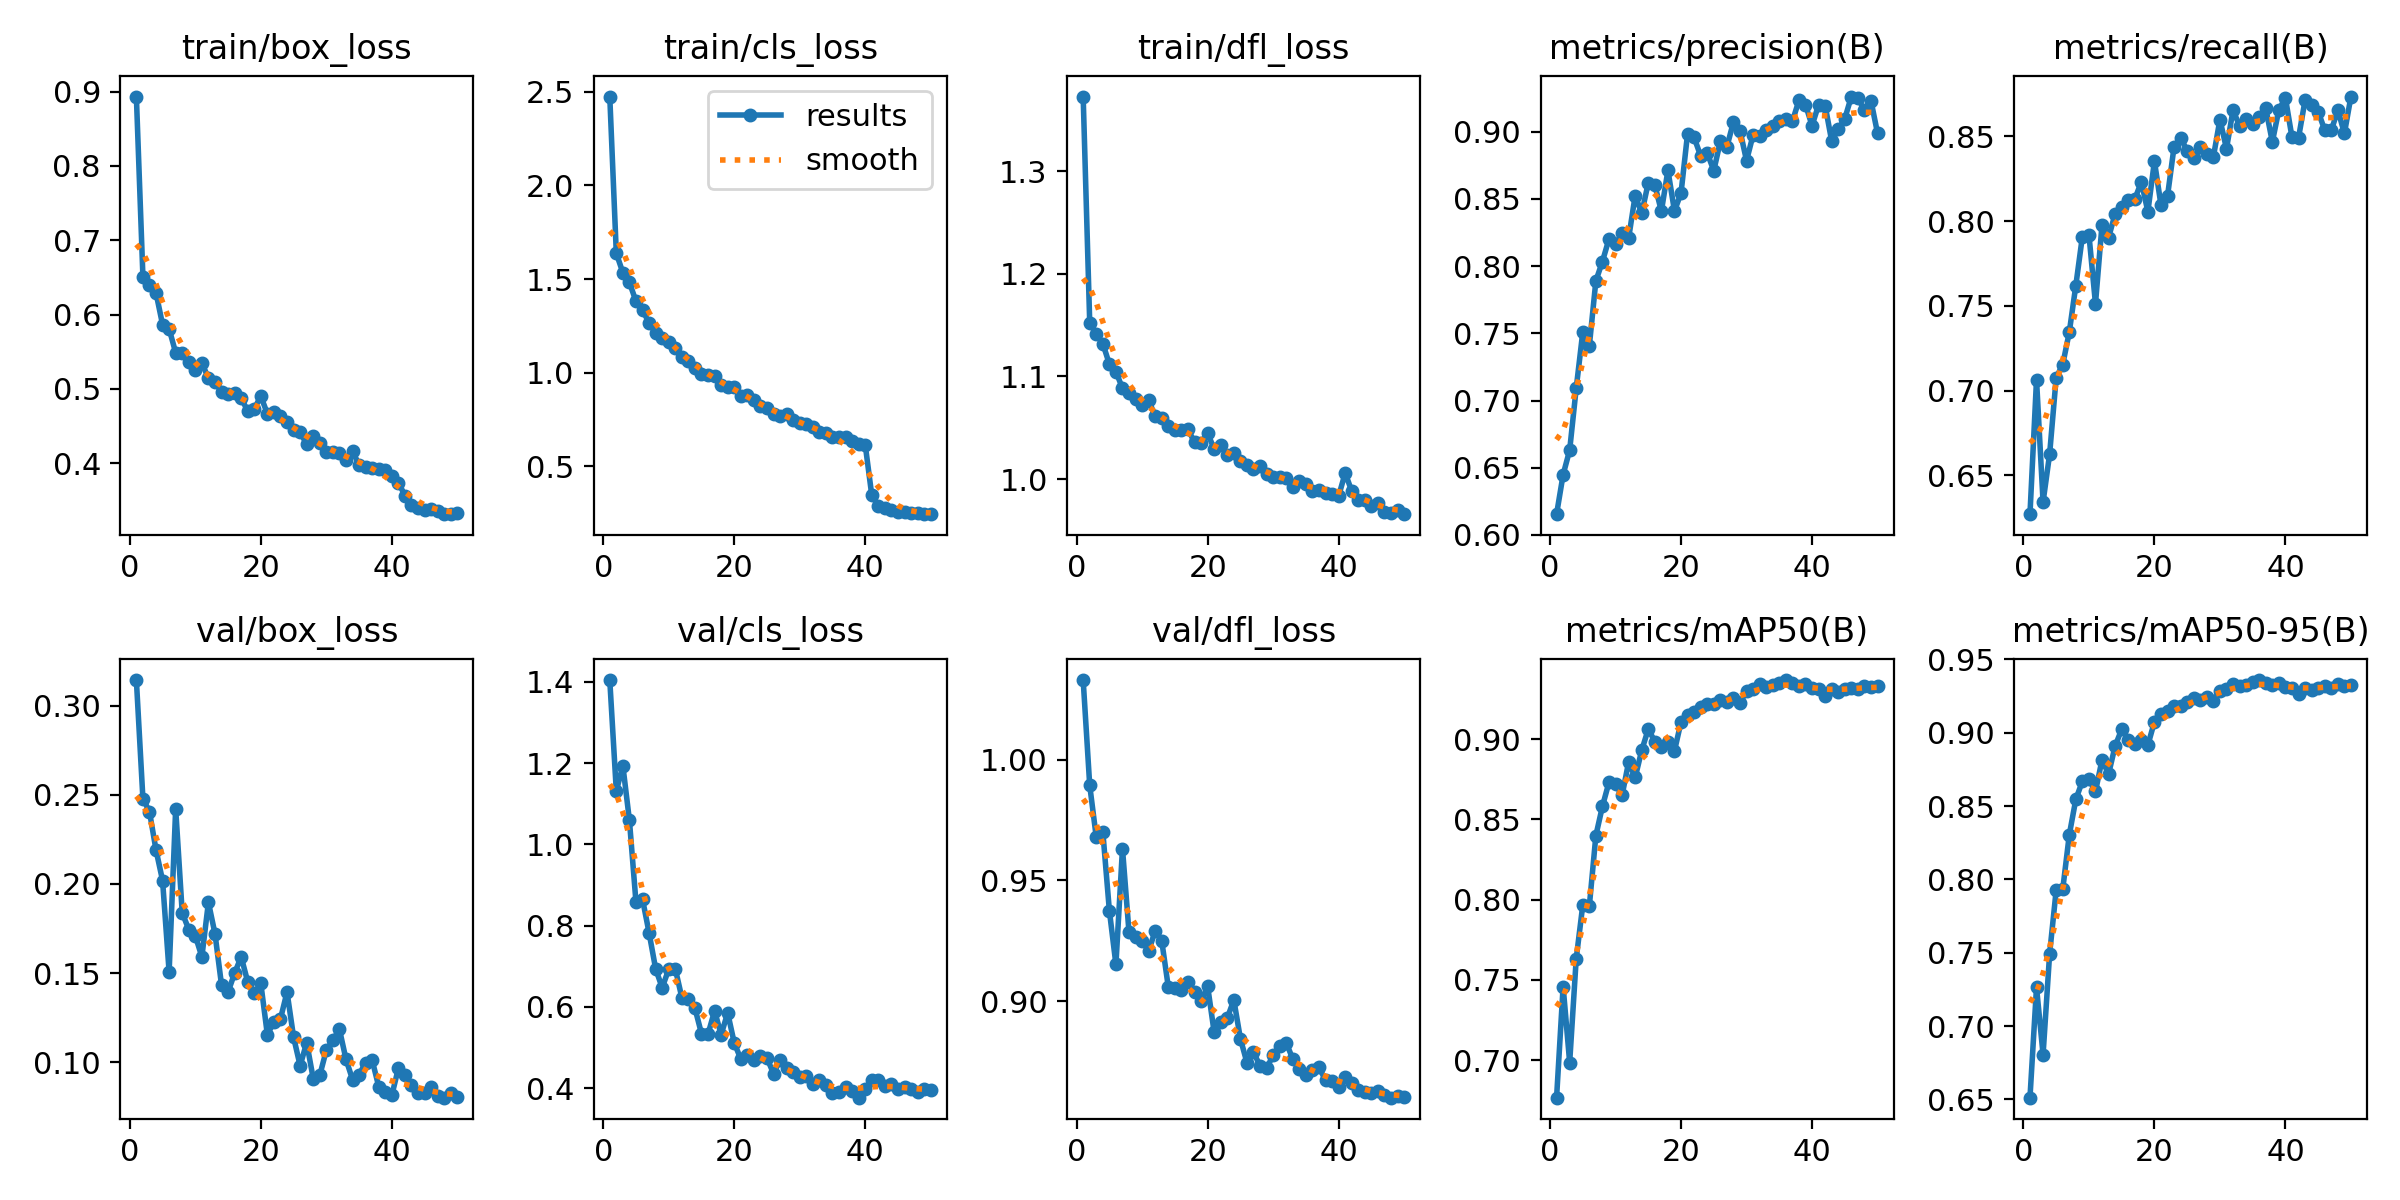

PR_curve.png not generated yet.
F1_curve.png not generated yet.
P_curve.png not generated yet.
R_curve.png not generated yet.
CONFUSION MATRIX: confusion_matrix.png


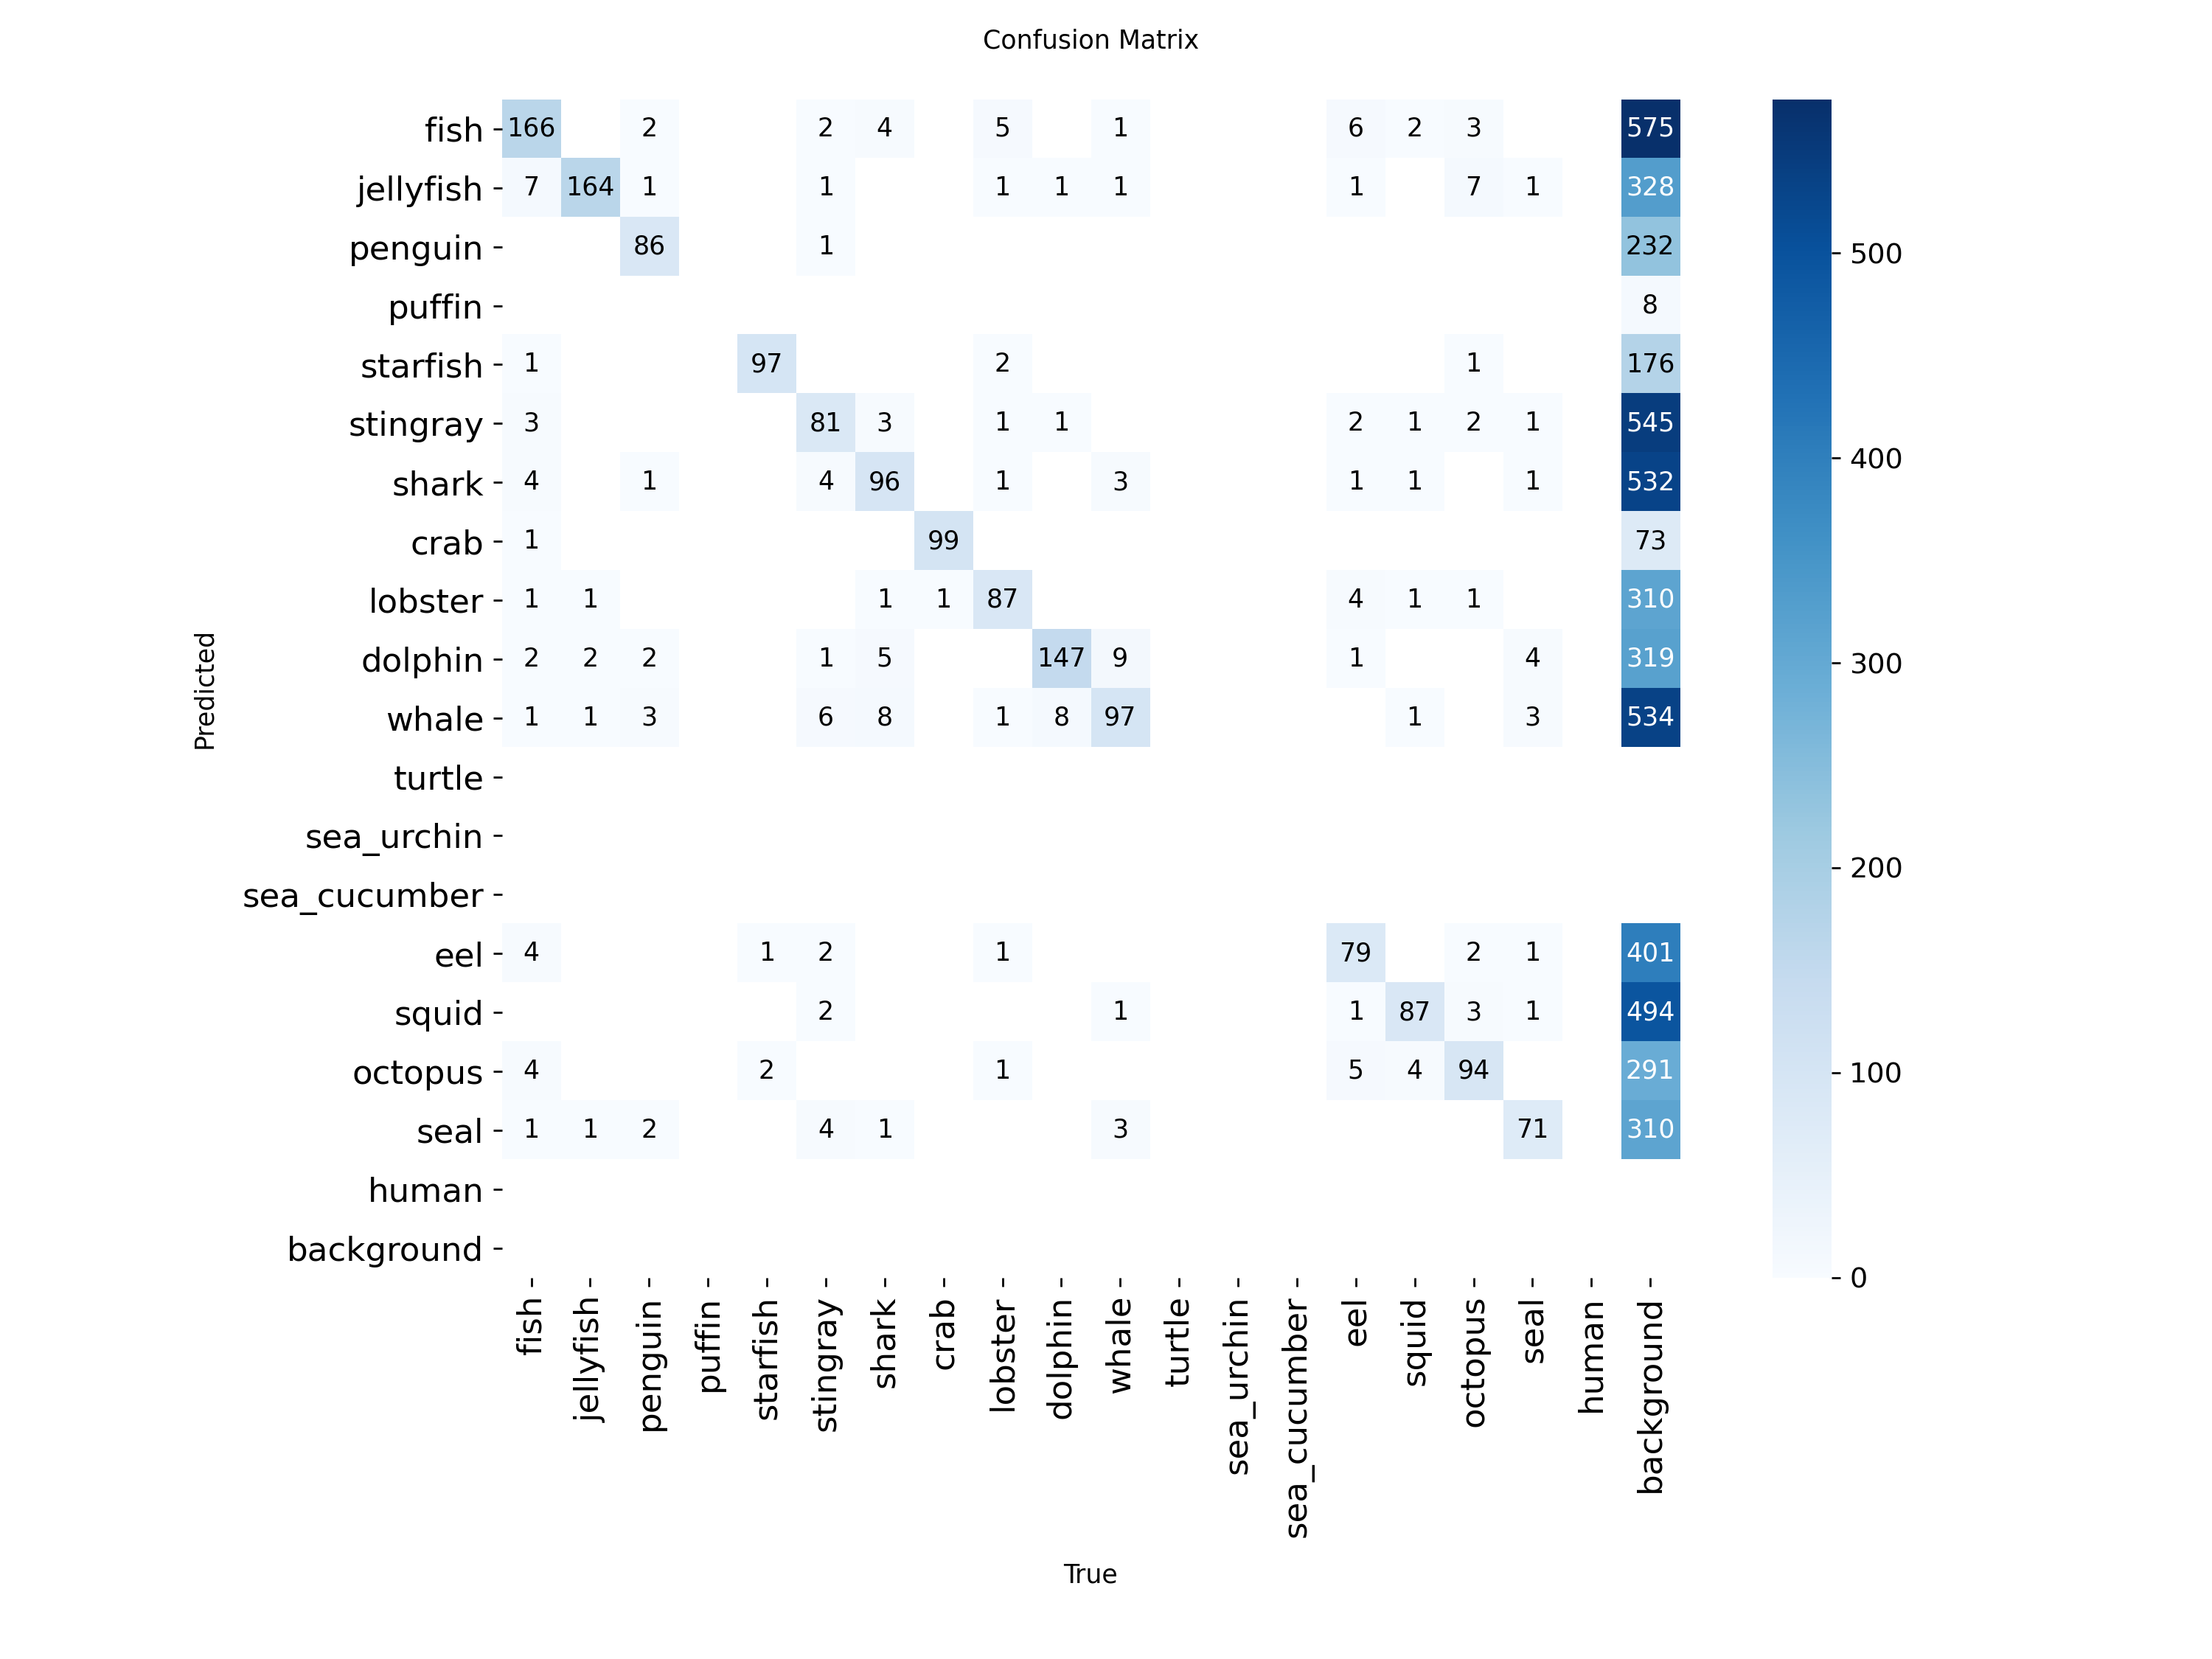

NORMALIZED CONFUSION MATRIX: confusion_matrix_normalized.png


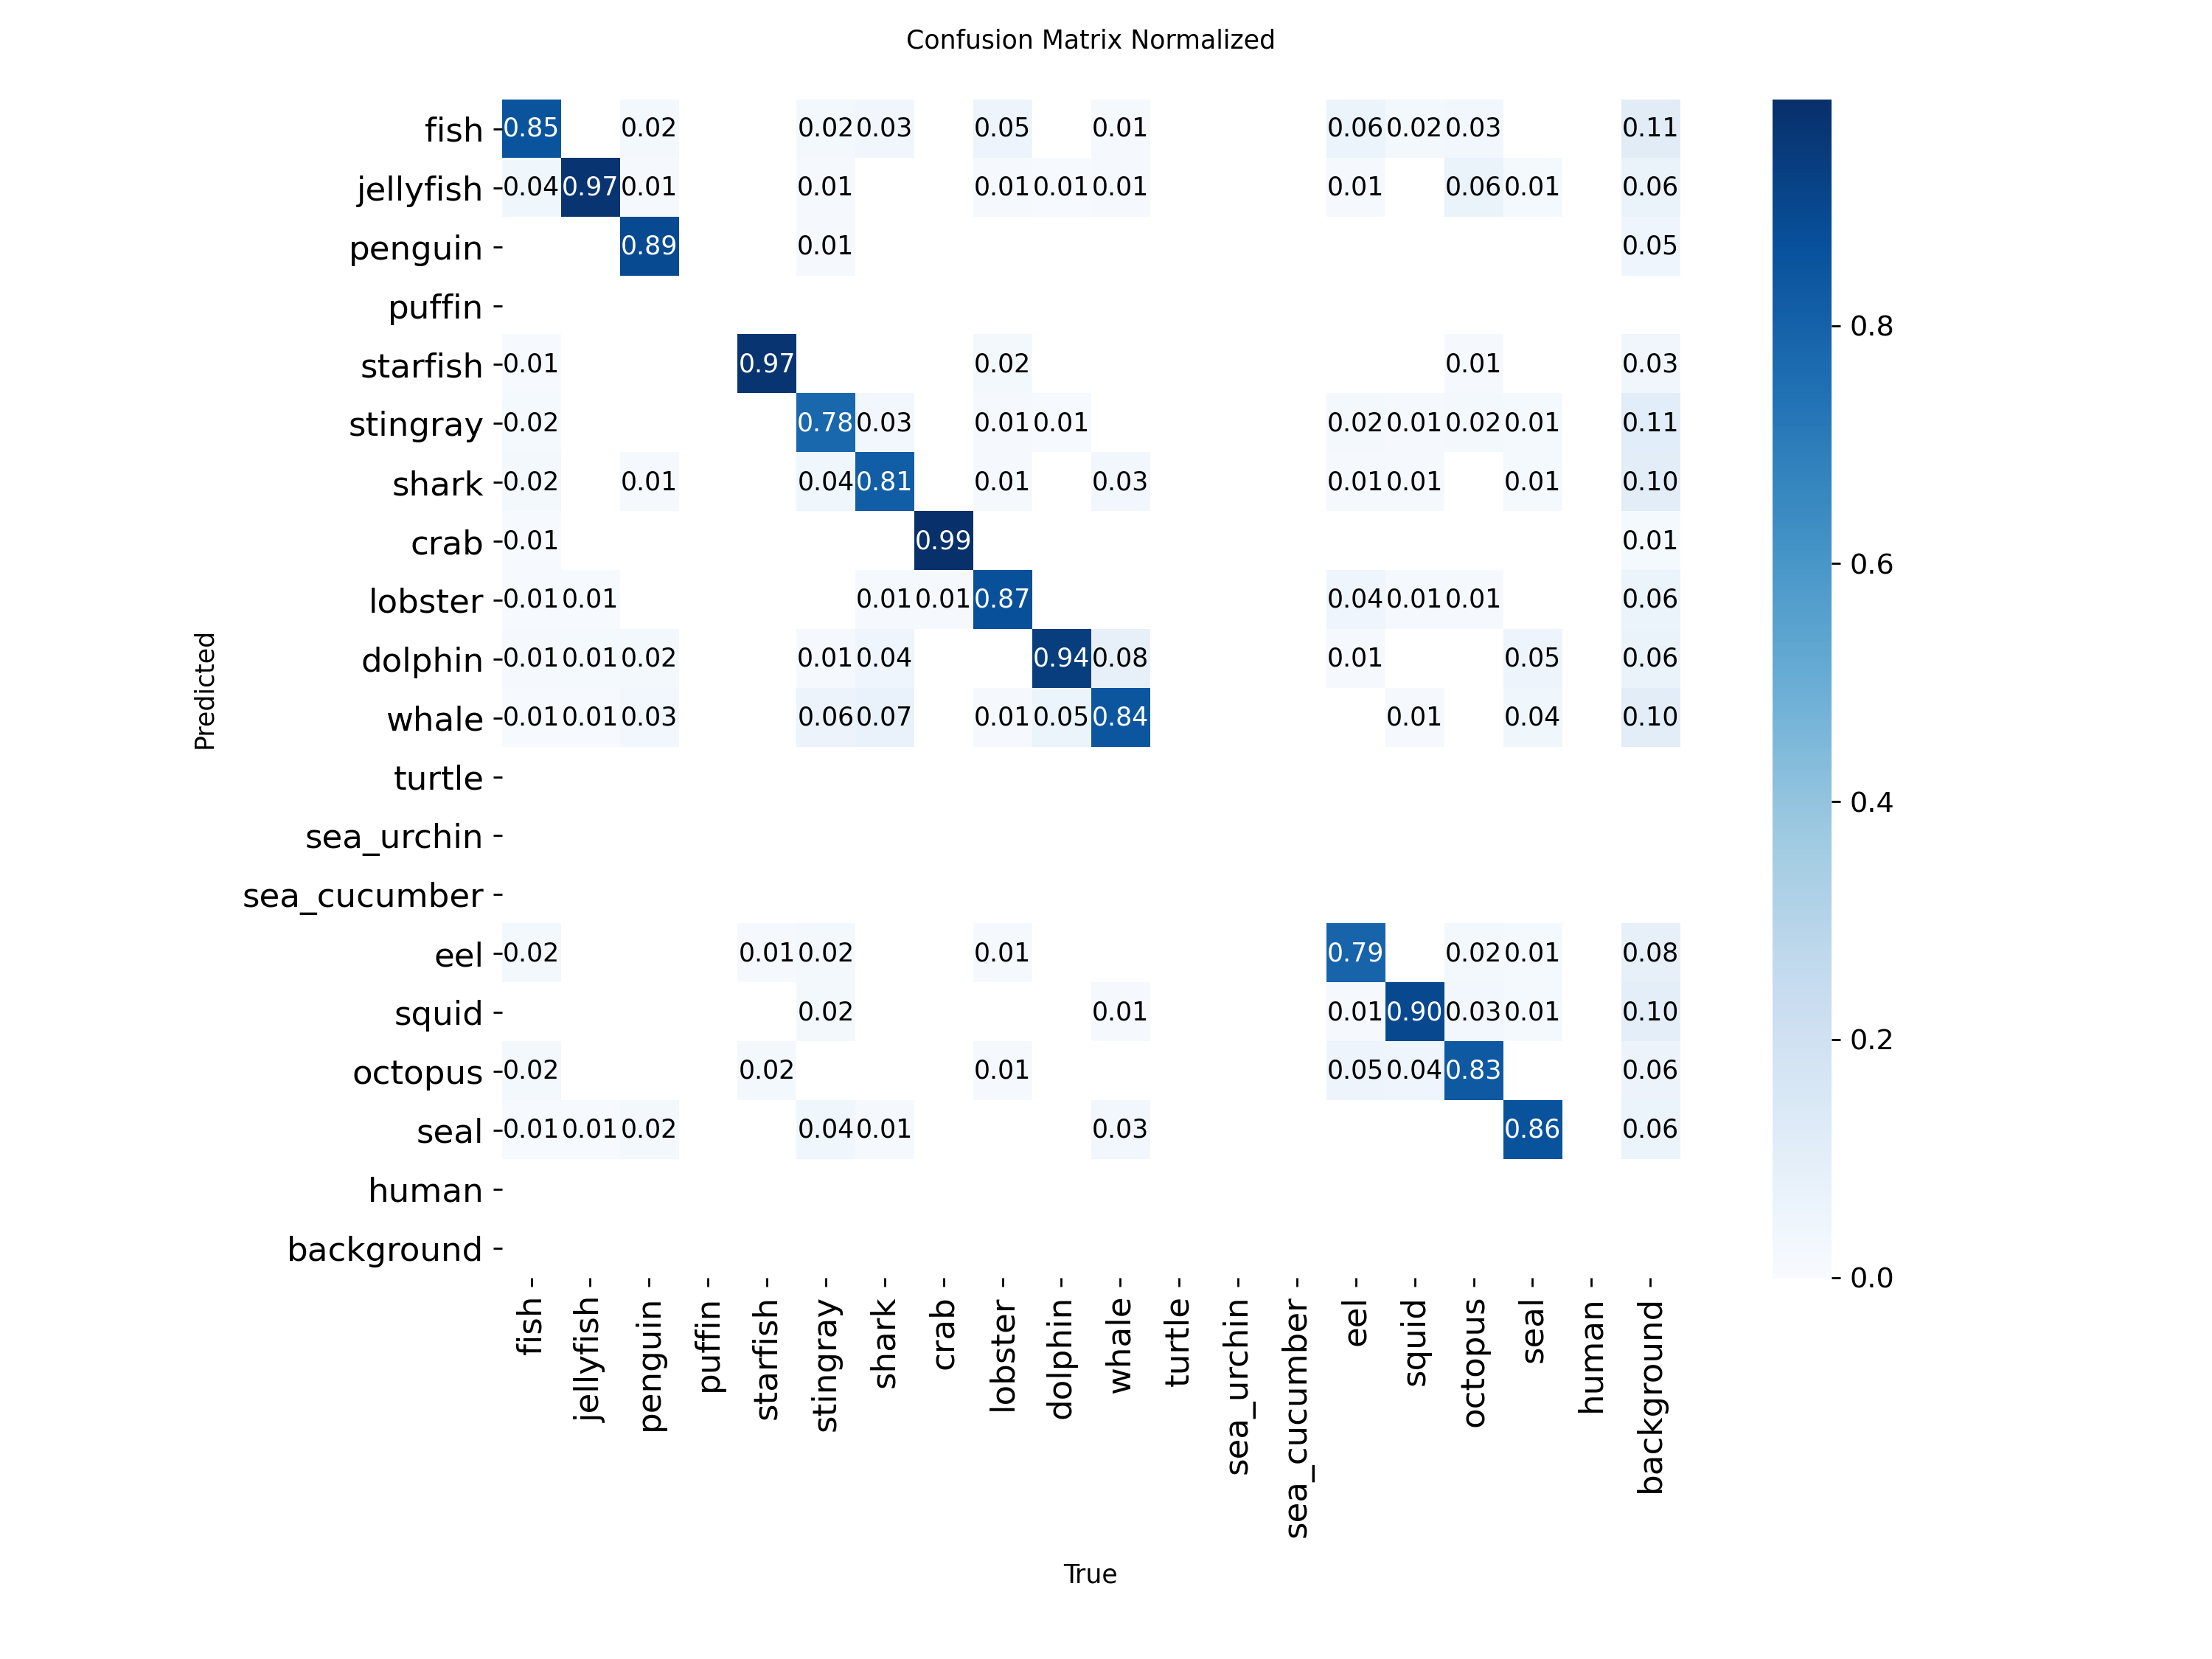

GROUND TRUTH LABELS: val_batch0_labels.jpg


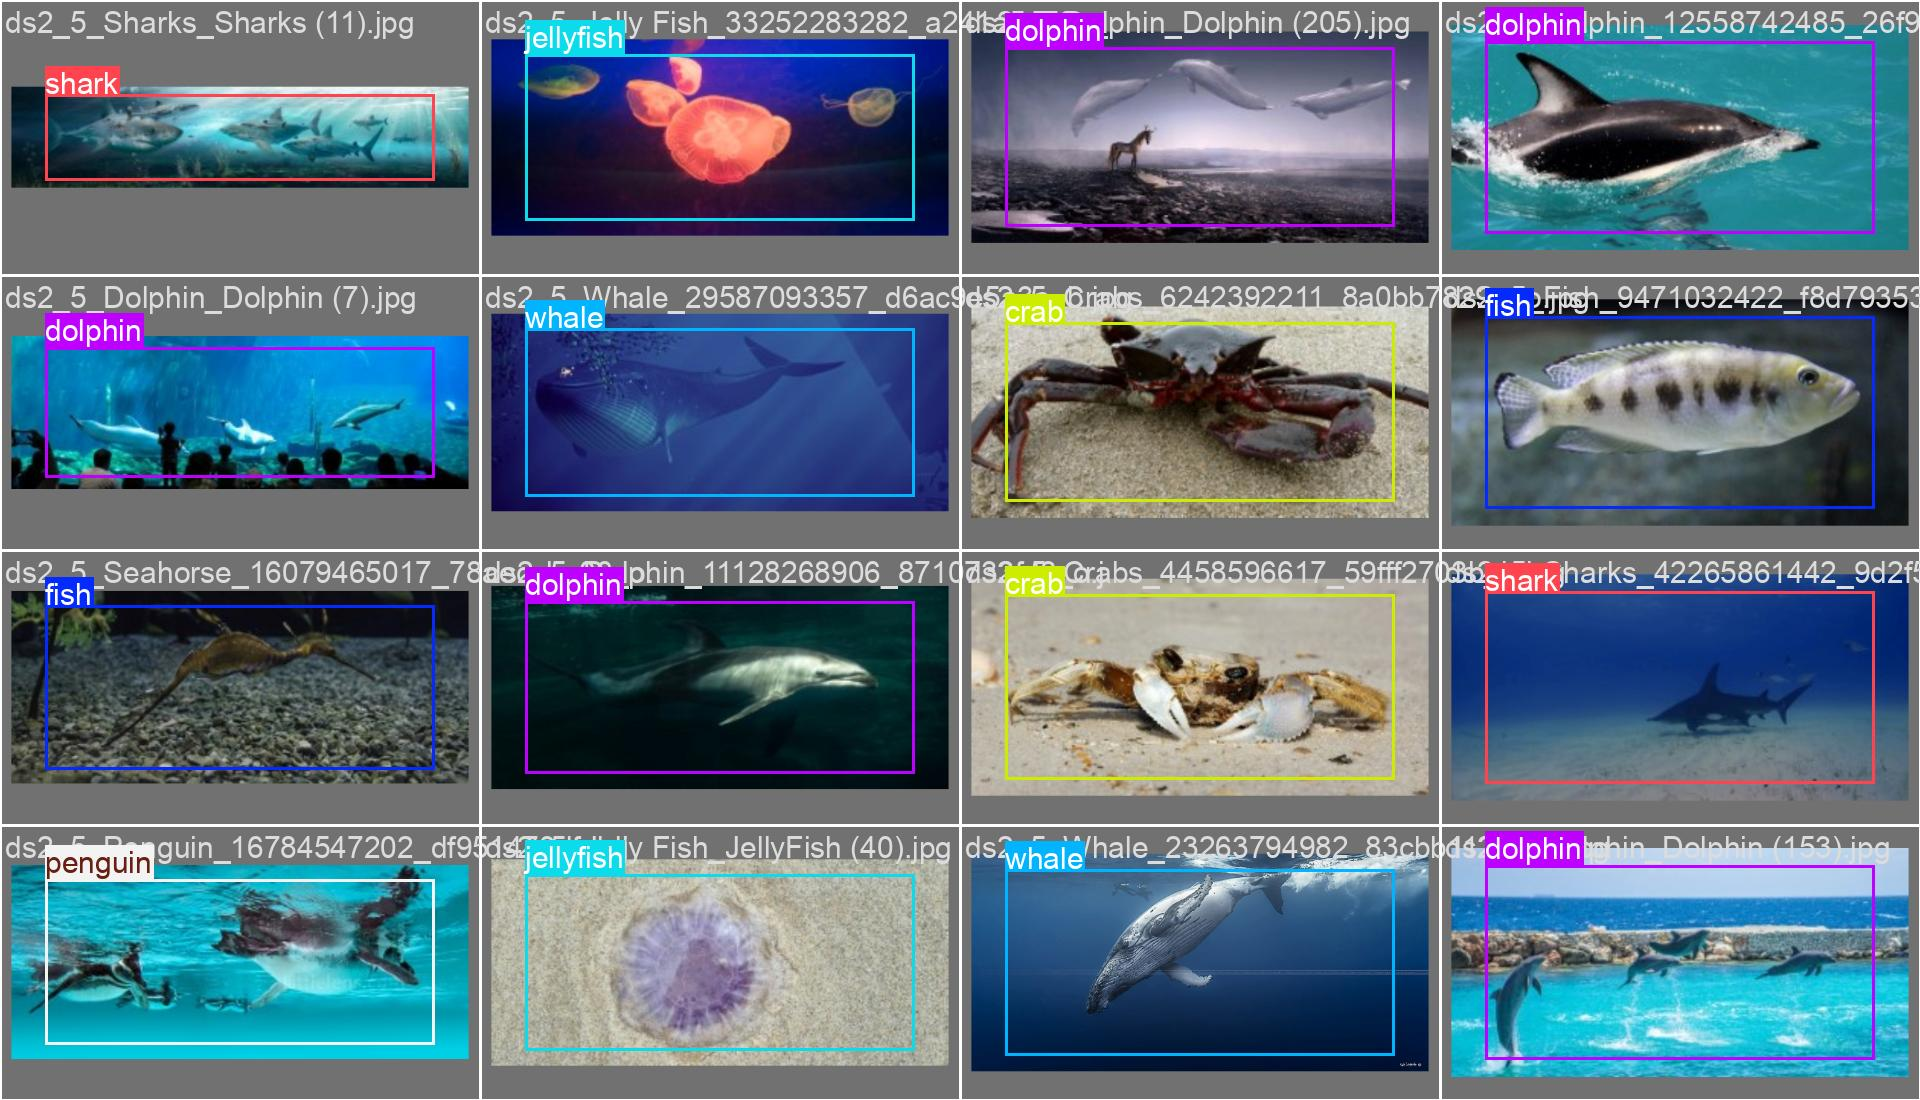

MODEL PREDICTIONS ON VALIDATION BATCH: val_batch0_pred.jpg


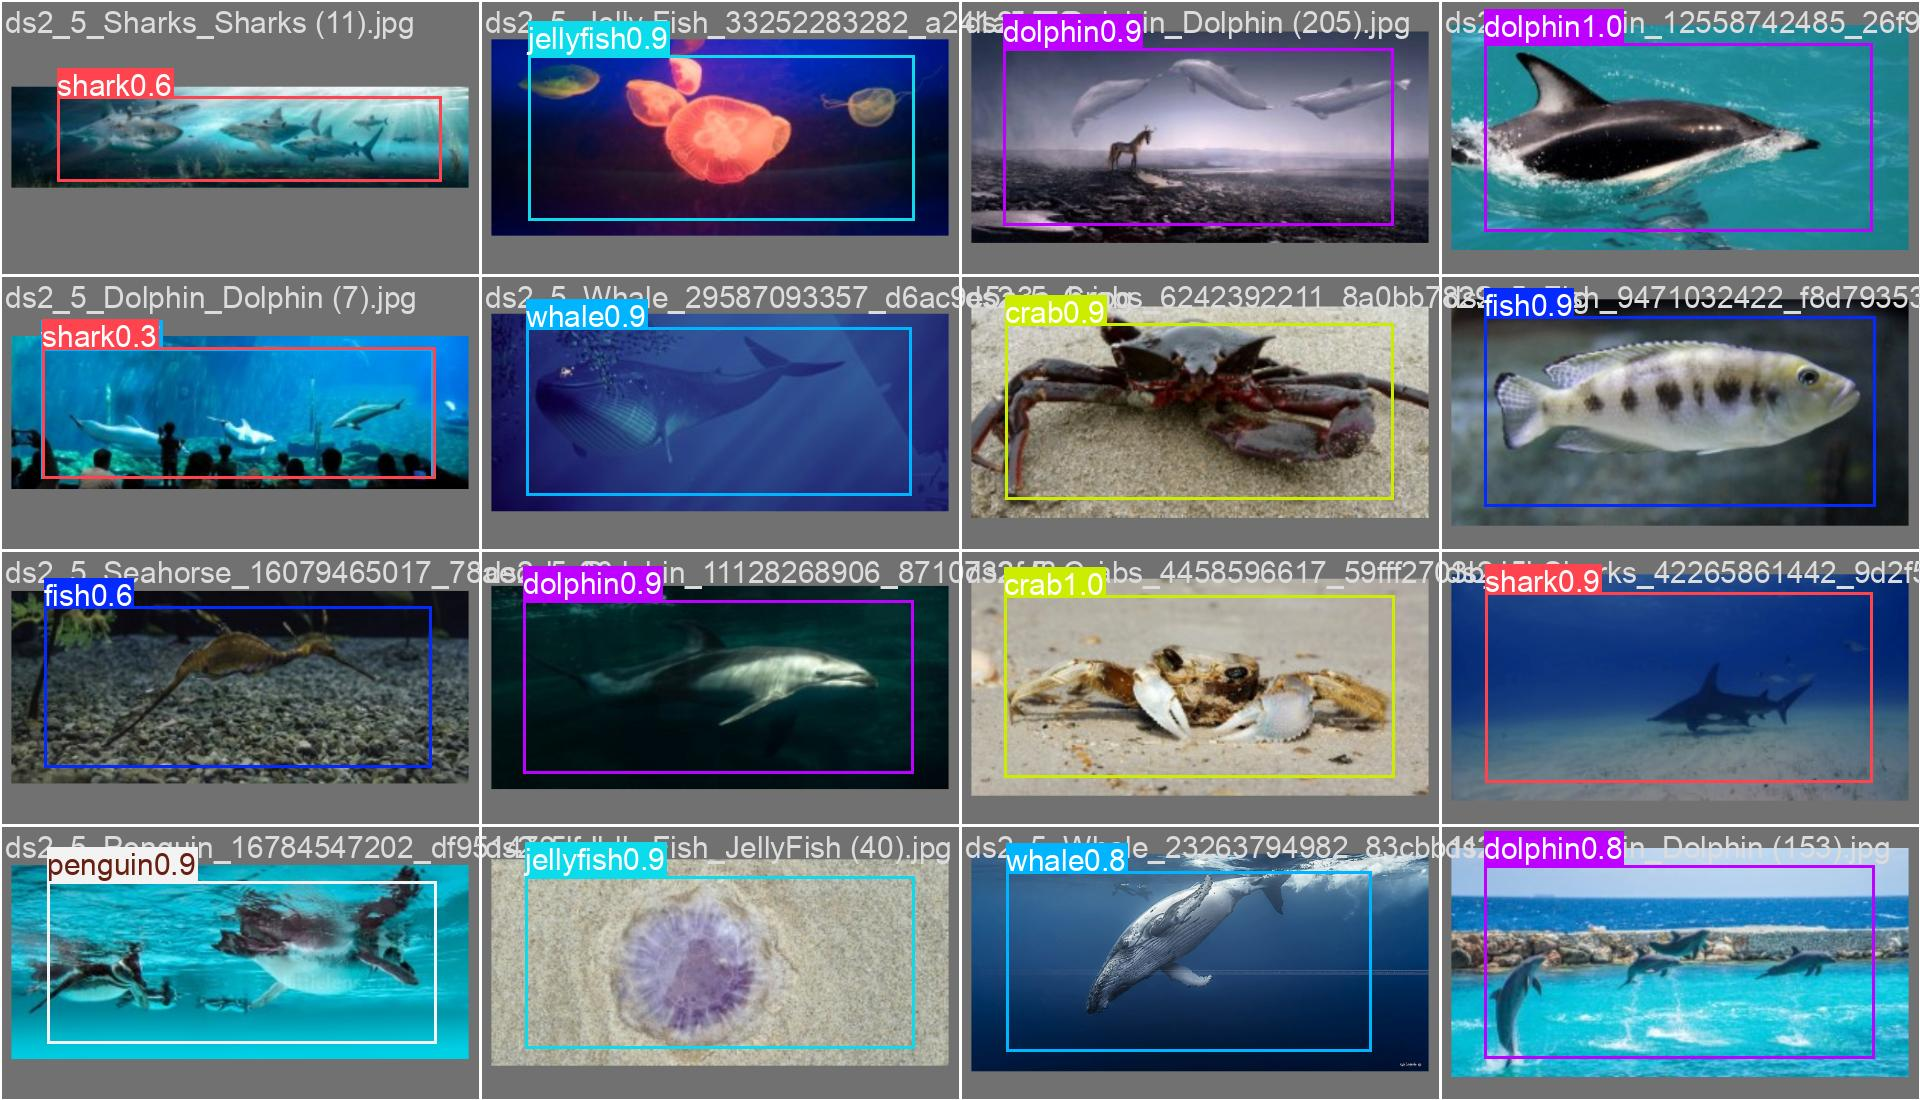

In [6]:
from IPython.display import Image, display
from pathlib import Path
import pandas as pd

RUN_DIR = Path("/content/AquaYOLO/runs/yolo_train/colab_run")

def show_graph(image_filename, title):
    p = RUN_DIR / image_filename
    if p.exists():
        print("=" * 75)
        print(f"{title}: {p.name}")
        print("=" * 75)
        display(Image(filename=str(p), width=900))
    else:
        print(f"{image_filename} not generated yet.")

# 1. Training & Validation Results (Losses, Precision, Recall, mAP50, mAP50-95)
show_graph("results.png", "TRAINING & VALIDATION METRICS OVER EPOCHS")

# 2. Precision-Recall Curve
show_graph("PR_curve.png", "PRECISION-RECALL (PR) CURVE")

# 3. F1-Confidence Curve
show_graph("F1_curve.png", "F1-SCORE VS CONFIDENCE CURVE")

# 4. Precision & Recall vs Confidence Curves
show_graph("P_curve.png", "PRECISION VS CONFIDENCE CURVE")
show_graph("R_curve.png", "RECALL VS CONFIDENCE CURVE")

# 5. Confusion Matrices
show_graph("confusion_matrix.png", "CONFUSION MATRIX")
show_graph("confusion_matrix_normalized.png", "NORMALIZED CONFUSION MATRIX")

# 6. Visual Detections on Validation Set (Ground Truth vs Model Prediction)
show_graph("val_batch0_labels.jpg", "GROUND TRUTH LABELS")
show_graph("val_batch0_pred.jpg", "MODEL PREDICTIONS ON VALIDATION BATCH")

## 📋 Step 7: View Numerical Metrics Table (Epoch by Epoch)

In [7]:
results_csv = RUN_DIR / "results.csv"
if results_csv.exists():
    df = pd.read_csv(results_csv)
    df.columns = [c.strip() for c in df.columns]
    print("\n--- FINAL EPOCHS SUMMARY ---")
    display(df.tail(10))
else:
    print("results.csv not found.")


--- FINAL EPOCHS SUMMARY ---


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
40,41,4425.92,0.37399,0.34553,1.00583,0.92013,0.84951,0.93095,0.93053,0.09660,0.41932,0.86835,0.000045,0.000045,0.000045
41,42,4532.83,0.35670,0.29022,0.98825,0.91953,0.84927,0.92676,0.92634,0.09257,0.42087,0.86614,0.000038,0.000038,0.000038
42,43,4633.65,0.34331,0.28041,0.97920,0.89308,0.87148,0.93090,0.93061,0.08706,0.40563,0.86313,0.000031,0.000031,0.000031
43,44,4733.80,0.33987,0.26717,0.97924,0.90174,0.86837,0.92946,0.92907,0.08277,0.40983,0.86223,0.000025,0.000025,0.000025
44,45,4833.65,0.33697,0.25959,0.97367,0.90979,0.86467,0.93090,0.93062,0.08270,0.39723,0.86178,0.000019,0.000019,0.000019
45,46,4933.22,0.33917,0.25905,0.97706,0.92625,0.85369,0.93205,0.93168,0.08613,0.40291,0.86263,0.000015,0.000015,0.000015
46,47,5033.31,0.33544,0.25381,0.96749,0.92526,0.85355,0.93099,0.93065,0.08124,0.39874,0.86100,0.000011,0.000011,0.000011
47,48,5133.21,0.33161,0.25432,0.96695,0.91591,0.86564,0.93326,0.93300,0.08007,0.39008,0.85996,0.000008,0.000008,0.000008
48,49,5232.89,0.33249,0.24555,0.96961,0.92306,0.85183,0.93223,0.93191,0.08262,0.39837,0.86072,0.000006,0.000006,0.000006
49,50,5333.44,0.33321,0.24725,0.96578,0.89889,0.87356,0.93281,0.93241,0.08033,0.39520,0.86017,0.000005,0.000005,0.000005


## 🧠 Step 8: (Optional) Train Custom AquaYOLO Architecture
AquaYOLO model with CSPDarknet backbone, Spectral Attenuation Compensator (SAC), and Turbidity Contrast Gate (TCG).

In [ ]:
# Train custom AquaYOLO model
!python src/aquayolo/train.py \
    --data "{DATA_YAML_PATH.parent}" \
    --epochs 30 \
    --batch 4 \
    --size 640 \
    --lr 0.0001 \
    --out ./runs/aquayolo_custom_colab

# Show AquaYOLO loss curves
aqua_loss_plot = Path("./runs/aquayolo_custom_colab/loss_curve.png")
if aqua_loss_plot.exists():
    display(Image(filename=str(aqua_loss_plot), width=800))
aqua_comp_plot = Path("./runs/aquayolo_custom_colab/loss_components.png")
if aqua_comp_plot.exists():
    display(Image(filename=str(aqua_comp_plot), width=900))

## 📥 Step 9: Download Training Results to Local System


In [9]:
import shutil
import os
from google.colab import files

# --- Configuration ---
RUNS_DIR = "/content/AquaYOLO/runs"
OUTPUT_ZIP_NAME = "AquaYOLO_training_results"

# --- Zip and Download ---
if os.path.exists(RUNS_DIR) and os.listdir(RUNS_DIR):
    print(f"📦 Zipping '{RUNS_DIR}' ...")
    zip_path = shutil.make_archive(
        base_name=f"/content/{OUTPUT_ZIP_NAME}",
        format="zip",
        root_dir=os.path.dirname(RUNS_DIR),
        base_dir=os.path.basename(RUNS_DIR)
    )
    zip_size_mb = os.path.getsize(zip_path) / (1024 * 1024)
    print(f"✅ Created: {zip_path} ({zip_size_mb:.1f} MB)")

    # List what's included
    run_folders = [d for d in os.listdir(RUNS_DIR) if os.path.isdir(os.path.join(RUNS_DIR, d))]
    print(f"\n📂 Run folders included ({len(run_folders)}):")
    for folder in sorted(run_folders):
        folder_path = os.path.join(RUNS_DIR, folder)
        num_files = sum(len(f) for _, _, f in os.walk(folder_path))
        print(f"   • {folder}/ ({num_files} files)")

    # Download to local machine
    print(f"\n⬇️  Downloading {OUTPUT_ZIP_NAME}.zip ...")
    files.download(zip_path)
    print("🎉 Check your browser's Downloads folder!")
else:
    print(f"❌ No runs found at '{RUNS_DIR}'. Run training first.")


📦 Zipping '/content/AquaYOLO/runs' ...
✅ Created: /content/AquaYOLO_training_results.zip (538.9 MB)

📂 Run folders included (2):
   • detect/ (12 files)
   • yolo_train/ (29 files)

⬇️  Downloading AquaYOLO_training_results.zip ...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

🎉 Check your browser's Downloads folder!


In [10]:
import shutil
import os
from google.colab import files

# --- Configuration ---
RUNS_DIR = "/content/AquaYOLO/runs"
OUTPUT_ZIP_NAME = "AquaYOLO_training_results"

# --- Zip and Download ---
if os.path.exists(RUNS_DIR) and os.listdir(RUNS_DIR):
    print(f"📦 Zipping '{RUNS_DIR}' ...")
    zip_path = shutil.make_archive(
        base_name=f"/content/{OUTPUT_ZIP_NAME}",
        format="zip",
        root_dir=os.path.dirname(RUNS_DIR),
        base_dir=os.path.basename(RUNS_DIR)
    )
    zip_size_mb = os.path.getsize(zip_path) / (1024 * 1024)
    print(f"✅ Created: {zip_path} ({zip_size_mb:.1f} MB)")

    # List what's included
    run_folders = [d for d in os.listdir(RUNS_DIR) if os.path.isdir(os.path.join(RUNS_DIR, d))]
    print(f"\n📂 Run folders included ({len(run_folders)}):")
    for folder in sorted(run_folders):
        folder_path = os.path.join(RUNS_DIR, folder)
        num_files = sum(len(f) for _, _, f in os.walk(folder_path))
        print(f"   • {folder}/ ({num_files} files)")

    # Download to local machine
    print(f"\n⬇️  Downloading {OUTPUT_ZIP_NAME}.zip ...")
    files.download(zip_path)
    print("🎉 Check your browser's Downloads folder!")
else:
    print(f"❌ No runs found at '{RUNS_DIR}'. Run training first.")


📦 Zipping '/content/AquaYOLO/runs' ...
✅ Created: /content/AquaYOLO_training_results.zip (538.9 MB)

📂 Run folders included (2):
   • detect/ (12 files)
   • yolo_train/ (29 files)

⬇️  Downloading AquaYOLO_training_results.zip ...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

🎉 Check your browser's Downloads folder!


In [11]:
import shutil
import os
from google.colab import files

# --- Zip the ENTIRE project folder ---
PROJECT_DIR = "/content/AquaYOLO"
OUTPUT_ZIP_NAME = "AquaYOLO_full_project"

# Exclude raw dataset images to keep zip size manageable
EXCLUDE_DIRS = {"datasets", "raw_downloads"}  # add folder names to skip if needed

def zip_filter(directory, contents):
    """Skip large raw dataset folders to keep zip size reasonable."""
    excluded = []
    for item in contents:
        if item in EXCLUDE_DIRS:
            excluded.append(item)
            print(f"   ⏭️  Skipping: {os.path.join(directory, item)}")
    return excluded

if os.path.exists(PROJECT_DIR):
    print(f"📦 Zipping entire project '{PROJECT_DIR}' ...")
    print("   (This includes model weights, runs, source code, configs)\n")

    zip_path = shutil.make_archive(
        base_name=f"/content/{OUTPUT_ZIP_NAME}",
        format="zip",
        root_dir="/content",
        base_dir="AquaYOLO"
    )

    zip_size_mb = os.path.getsize(zip_path) / (1024 * 1024)
    print(f"\n✅ Created: {zip_path} ({zip_size_mb:.1f} MB)")

    # Show what's included
    print(f"\n📂 Contents summary:")
    for item in sorted(os.listdir(PROJECT_DIR)):
        item_path = os.path.join(PROJECT_DIR, item)
        if os.path.isdir(item_path):
            num_files = sum(len(f) for _, _, f in os.walk(item_path))
            print(f"   📁 {item}/ ({num_files} files)")
        else:
            size_mb = os.path.getsize(item_path) / (1024 * 1024)
            print(f"   📄 {item} ({size_mb:.1f} MB)")

    # Download
    print(f"\n⬇️  Downloading {OUTPUT_ZIP_NAME}.zip ({zip_size_mb:.1f} MB) ...")
    files.download(zip_path)
    print("🎉 Check your browser's Downloads folder!")
else:
    print(f"❌ Project not found at '{PROJECT_DIR}'.")


📦 Zipping entire project '/content/AquaYOLO' ...
   (This includes model weights, runs, source code, configs)


✅ Created: /content/AquaYOLO_full_project.zip (893.0 MB)

📂 Contents summary:
   📁 .git/ (28 files)
   📄 .gitignore (0.0 MB)
   📄 AquaYOLO_Colab_Training_and_Evaluation.ipynb (0.0 MB)
   📄 FishInv.pt (83.6 MB)
   📄 MegaFauna.pt (83.6 MB)
   📄 README.md (0.0 MB)
   📁 __pycache__/ (1 files)
   📄 audit_dataset.py (0.0 MB)
   📄 check_batch4_memory.py (0.0 MB)
   📄 check_megafauna_compat.py (0.0 MB)
   📄 check_pretrained_compatibility.py (0.0 MB)
   📄 check_target_collisions.py (0.0 MB)
   📄 confidence_sweep.py (0.0 MB)
   📄 dataset_merger.py (0.0 MB)
   📄 enable_class_sampling.py (0.0 MB)
   📄 enable_multiscale_targets.py (0.0 MB)
   📄 enable_train_augmentation.py (0.0 MB)
   📄 error_analysis.py (0.0 MB)
   📄 fast_rebalance_dataset.py (0.0 MB)
   📄 finalize_dataset.py (0.0 MB)
   📄 make_demo_gallery.py (0.0 MB)
   📄 make_megafauna_init.py (0.0 MB)
   📄 merge_fjordfish.py (0.0 MB)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

🎉 Check your browser's Downloads folder!
